<a href="https://colab.research.google.com/github/KatiaItzelCortes/Simulaci-n-2/blob/main/Modelo_SIR_con_pyMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Modelo SIR con PyMC

El modelo **SIR** divide a una población en tres compartimentos dinámicos:
- $S(t)$: Susceptibles
- $I(t)$: Infectados
- $R(t)$: Removidos

Su dinámica está dada por el sistema:
$$\begin{align*} \frac{dS}{dt} &= -aSI \\ \frac{dI}{dt} &= aSI - bI \\ \frac{dR}{dt} &= bI \end{align*}$$
Donde $a$ es la tasa de transmisión y $b$ la tasa de recuperación.

El enfoque bayesiano asume que los parámetros $a$ y $b$ son variables aleatorias con una distribución de probabilidad previa (*prior*). Utilizando el Teorema de Bayes, actualizamos nuestra creencia sobre estos parámetros al observar los datos empíricos (*likelihood* o verosimilitud) para obtener una distribución posterior (*posterior*).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import pymc as pm
import pytensor.tensor as pt
import arviz as az

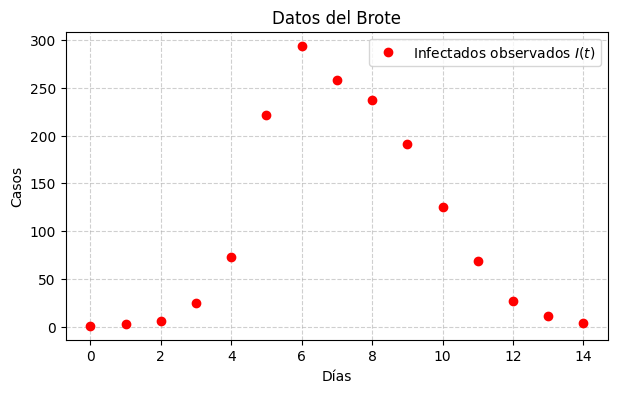

In [21]:
t_data = np.arange(15)
I_data = np.array([1, 3, 6, 25, 73, 222, 294, 258, 237, 191, 125, 69, 27, 11, 4])

# Población N=763
y0 = [762, 1, 0] # [S0, I0, R0]

plt.figure(figsize=(7, 4))
plt.plot(t_data, I_data, 'ro', label='Infectados observados $I(t)$')
plt.title('Datos del Brote')
plt.xlabel('Días')
plt.ylabel('Casos')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

Modelo Numérico y Conexión con PyTensor

In [22]:
from pytensor.compile.ops import as_op

def sir_model(y, t, a, b):
    S, I, R = y
    return [-a * S * I, a * S * I - b * I, b * I]

def solve_sir(a, b):
    sol = odeint(sir_model, y0, t_data, args=(float(a), float(b)))
    return sol[:, 1]

@as_op(itypes=[pt.dscalar, pt.dscalar], otypes=[pt.dvector])
def simulate_sir_op(a, b):
    return solve_sir(a, b)

/tmp/ipykernel_3372/384078715.py:11: FutureWarning: pytensor.as_op is deprecated and will be removed in a future release. Please use pytensor.wrap_py instead.
  @as_op(itypes=[pt.dscalar, pt.dscalar], otypes=[pt.dvector])


Construcción del Modelo MCMC con PyMC

Definiremos nuestras distribuciones *a priori* (priors) basándonos en restricciones

In [23]:
with pm.Model() as sir_pymc_model:
    # 1. Priors
    a_prior = pm.HalfNormal('a', sigma=0.01)
    b_prior = pm.HalfNormal('b', sigma=1.0)

    sigma = pm.HalfNormal('sigma', sigma=50)

    # 2. Esperanza
    I_expected = simulate_sir_op(a_prior, b_prior)

    # 3. Likelihood
    Y_obs = pm.Normal('Y_obs', mu=I_expected, sigma=sigma, observed=I_data)

    # 4. Muestreo MCMC
    print("Iniciando muestreo MCMC...")
    trace = pm.sample(draws=2000, tune=1000, step=pm.Metropolis(), cores=1, return_inferencedata=True, progressbar=True)

Iniciando muestreo MCMC...


Output()

Resultados e Interpretación de Gráficas

Al aplicar la inferencia bayesiana obtenemos trazas de las simulaciones y distribuciones posteriores.

1. Gráficos de Traza (Trace Plots): Muestran el recorrido de la cadena de Markov. Se observa una convergencia adecuada
2. Distribuciones Posteriores: Los histogramas muestran la certidumbre sobre nuestros parámetros.

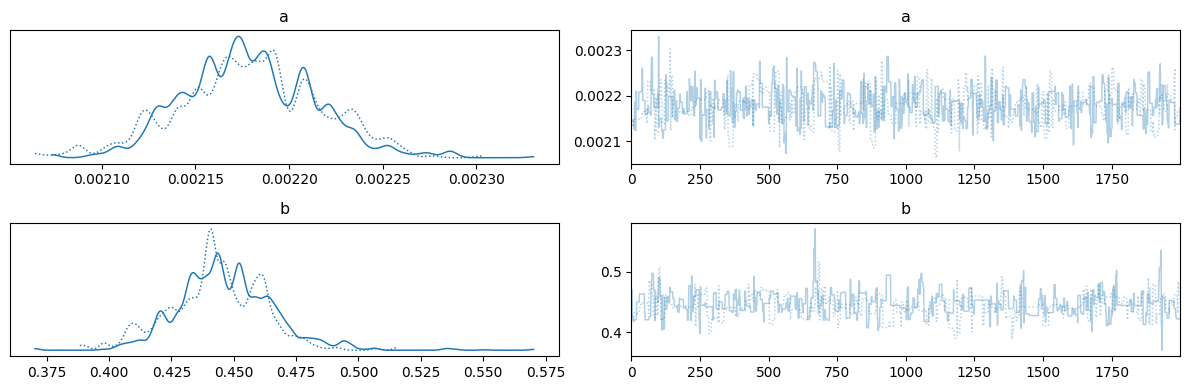

In [24]:
az.plot_trace(trace, var_names=['a', 'b'])
plt.tight_layout()
plt.show()

In [25]:
suma = az.summary(trace, var_names=['a', 'b'])
print("Estadístico Posterior")
print(suma)

a_fin = suma.loc['a', 'mean']
b_fin = suma.loc['b', 'mean']

print("SOLUCIÓN BAYESIANA")
print(f"Tasa de transmisión (a): {a_fin}")
print(f"Tasa de recuperación (b): {b_fin}")

t_smooth = np.linspace(0, 14, 100)
I_fit = odeint(sir_model, y0, t_smooth, args=(a_fin, b_fin))[:, 1]

Estadístico Posterior
    mean     sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  ess_tail  \
a  0.002  0.000   0.002    0.002      0.000    0.000     410.0     390.0   
b  0.445  0.019   0.407    0.477      0.001    0.001     342.0     247.0   

   r_hat  
a   1.01  
b   1.01  
SOLUCIÓN BAYESIANA
Tasa de transmisión (a): 0.002
Tasa de recuperación (b): 0.445


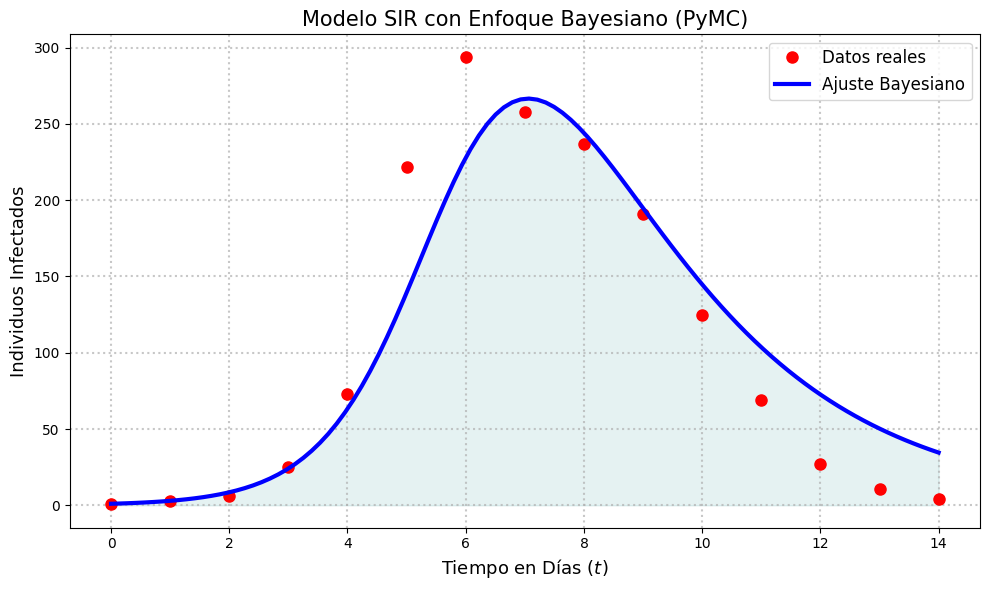

In [28]:
plt.figure(figsize=(10, 6))
plt.plot(t_data, I_data, 'ro', markersize=8, label='Datos reales')
plt.plot(t_smooth, I_fit, color='blue', linewidth=3,
         label=f'Ajuste Bayesiano')

plt.fill_between(t_smooth, I_fit, color='teal', alpha=0.1)
plt.title('Modelo SIR con Enfoque Bayesiano (PyMC)', fontsize=15)
plt.xlabel('Tiempo en Días ($t$)', fontsize=13)
plt.ylabel('Individuos Infectados', fontsize=13)
plt.legend(fontsize=12)
plt.grid(True, linestyle=':', linewidth=1.5, alpha=0.7)
plt.tight_layout()
plt.show()